In [99]:
import numpy as np
import matplotlib.pyplot as plt
import time
from lab07_engine import engine as eng
from lab07_engine import world_animate as animate
rng = np.random.default_rng()

Part A - Build the Core Engine

The engine is written with six main classes rather than four. Those being the four requested, (Body, World, Force, Integrator), and two additional classes to deal with collisions, Wall and Constraint. An instance of the wall class is just a container that holds two points and the cells it inhabits, if spatial gridding is being used, whereas the constraints class has two subclasses each with there own resolve method, Wall_Collisions and Body_Collisions, which deal with wall-body collisions and body-body collisions respectively. The Force class has six subclasses, (Drag, Gravity, Newtonion Gravity, Spring, Pivot Gravity, Coulombic Interactions), which each have apply and potential energy methods. The Integrator clas has three subclasses, (Euler, Euler_Cromer, Verlet), which each have step methods. The world has a record method which takes a name and a function and stores calls of the given function during a run as values in a dictionary under the given name. Force and torque are stored as accumulators in each body and are cleared after each step to be recalculated.

![alt text](<Blank diagram (1).png>)

The above UML class diagram includes all six of the main classes in my engine. Not all of the attributes and methods of the Body and World classes are shown as the diagram would be too cluttered, namely, anything to do with spatial gridding was omitted, as well as the accumulators for the body. The World class is shown to be associated with the Force and Constraint class as both sides have functions which are tied to the other. The World class is also shown to be related to the Body, Wall, and Integrator classes via aggregation, as instances of these classes make up the world but can exist outside of it. The multiplities by each connection at the World class show how many objects of each class can be used by one instance of the World class, with 0... meaning any amount. 

Part B - Validate Against Your Old Labs

Gravity

In lab 2, we looked at projectile motion from an energetic perspectve. I have pasted the code I used for one of the parts of lab 2 and recreated the simulation using my engine. From the plots, it is clear that the engine and the code from lab 2 agree. Indeed, the max value for energy drift between the two simulations is on the order of 0.0, so there is no discrepency, at least from an energy conservation perspective.

In [92]:
def simulate_projectile_2d(v0, theta_deg, dt, g):
    theta_rad = np.deg2rad(theta_deg)
    vx = v0*np.cos(theta_rad)
    vy = v0*np.sin(theta_rad)
    x = 0
    y = 0
    t = 0
    KE = 0.5*(vx**2+vy**2)
    PE = g*y
    E_total = KE + PE
    state = {'t':[t], 'x':[x], 'y':[y], 'Vx':[vx], 'Vy':[vy], 'KE':[KE], 'PE':[PE], 'E':[E_total]}
    while y>=0:
        vx_old = vx
        vy_old = vy
        vx += 0
        vy += -g*dt
        x += vx_old*dt
        y += vy_old*dt
        t += dt
        KE = 0.5*(vx**2+vy**2)
        PE = g*y
        E_total = KE + PE

        state['t'].append(t)
        state['x'].append(x)
        state['y'].append(y)
        state['Vx'].append(vx)
        state['Vy'].append(vy)
        state['KE'].append(KE)
        state['PE'].append(PE)
        state['E'].append(E_total)
    return state

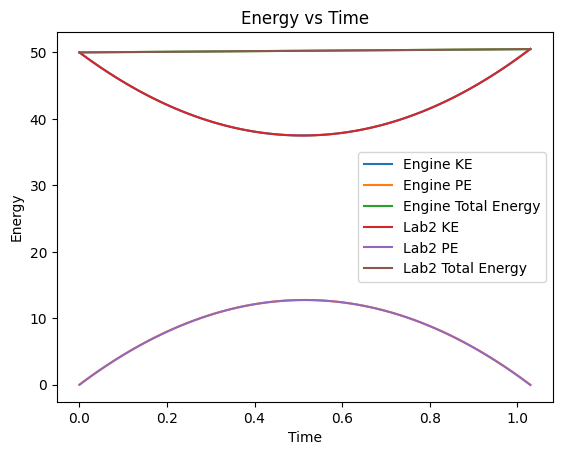

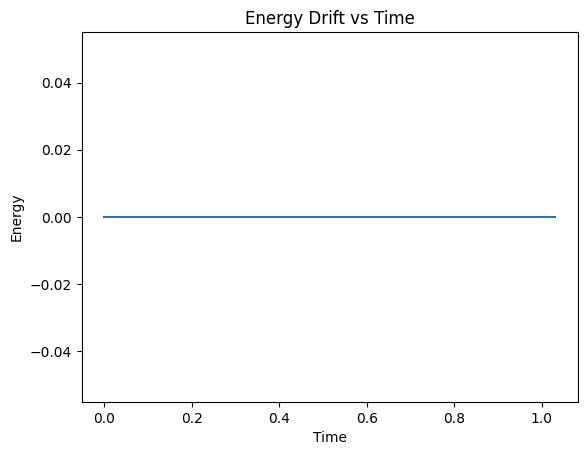

The max difference in total energy between the methods is 0.0


In [94]:
v0, theta, dt, g = 10, 30, 0.01, 9.81
Ball = eng.Body(v=v0*np.array((np.cos(np.deg2rad(theta)),np.sin(np.deg2rad(theta)))))
Sim = eng.World(integrator=eng.Euler(),forces=[eng.Gravity(g=9.81)], bodies=[Ball])
Sim.record('KE', lambda W: W.kinetic_energy())
Sim.record('PE', lambda W: W.potential_energy())
Sim.record('E', lambda W: W.total_energy())
Sim.record('t', lambda W: W.t)
Sim.run(dt, End_Condition= lambda W: W.bodies[0].r[1] < 0)
Lab2 = simulate_projectile_2d(v0, theta, dt, g)

plt.plot(Sim.history['t'], Sim.history['KE'], label= 'Engine KE')
plt.plot(Sim.history['t'], Sim.history['PE'], label= 'Engine PE')
plt.plot(Sim.history['t'], Sim.history['E'], label= 'Engine Total Energy')

plt.plot(Lab2['t'], Lab2['KE'], label= 'Lab2 KE')
plt.plot(Lab2['t'], Lab2['PE'], label= 'Lab2 PE')
plt.plot(Lab2['t'], Lab2['E'], label= 'Lab2 Total Energy')

plt.xlabel('Time')
plt.ylabel('Energy')
plt.title('Energy vs Time')
plt.legend()
plt.show()

plt.plot(Sim.history['t'], [s-p for s, p in zip(Sim.history['E'],Lab2['E'])])
plt.xlabel('Time')
plt.ylabel('Energy')
plt.title('Energy Drift vs Time')
plt.show()
print(f'The max difference in total energy between the methods is {max([s-p for s, p in zip(Sim.history['E'],Lab2['E'])])}')

Oscillator

In lab 3, we looked at oscillatory motion. I have pasted the code I used for one of the parts of lab 3 and recreated the simulation using my engine. From the plots, it is clear that the engine and the code from lab 3 agree. Indeed, the max value for energy drift between the two simulations is on the order of 10e-16, so there is no virtually no discrepency, at least from an energy conservation perspective.

In [90]:
k = 1.0
m = 1.0
Omega_0 = np.sqrt(k/m)
T = 2*np.pi/Omega_0

x_0 = 2.0
v_0 = 0.0
t_0 = 0.0

dt = 0.01

def x_exact_sol(t):
    return x_0 * np.cos(Omega_0 * t)

def v_exact_sol(t):
    return -x_0 * Omega_0 * np.sin(Omega_0 * t)

def simulate_sho(method, dt, n_periods = 5):
    """Simulates simple harmonic oscillator with 
    energy tracking, method is 'euler' or 'euler-cromer'
    """

    x = x_0
    v = v_0
    t = t_0
    KE = 0.5*m*v**2
    PE = 0.5*k*x**2
    E_total = KE + PE

    state = {'t':[t], 'x':[x], 'v':[v], 'KE':[KE], 'PE':[PE], 'E':[E_total]}

    run_time = n_periods*T

    while t<run_time:

        ax = - (k/m) * (x)

        if method == 'euler':
            x += v*dt
            v += ax*dt
        elif method == 'euler-cromer':
            v += ax*dt
            x += v*dt

        t += dt
        KE = 0.5*m*v**2
        PE = 0.5*k*x**2
        E_total = KE + PE

        state['t'].append(t)
        state['x'].append(x)
        state['v'].append(v)
        state['KE'].append(KE)
        state['PE'].append(PE)
        state['E'].append(E_total)

    return state

B1 = eng.Body(m=0, fixed=True)
B2 = eng.Body(m=m, r=(x_0, 0), v=(v_0, 0))
Spring = eng.Spring(B1, B2, r_0=0, k=k)
Sim = eng.World(eng.Euler_Cromer(), forces=[Spring], bodies=[B1, B2])

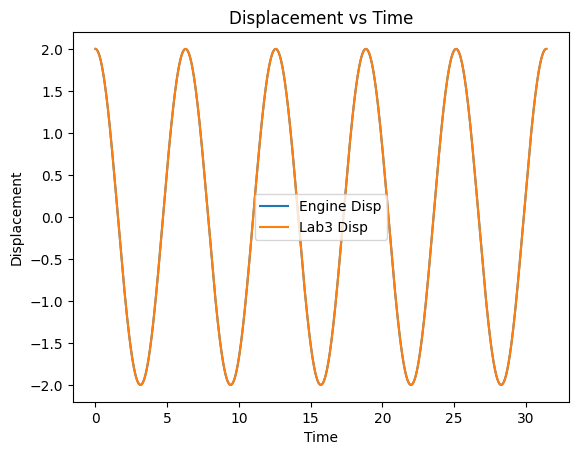

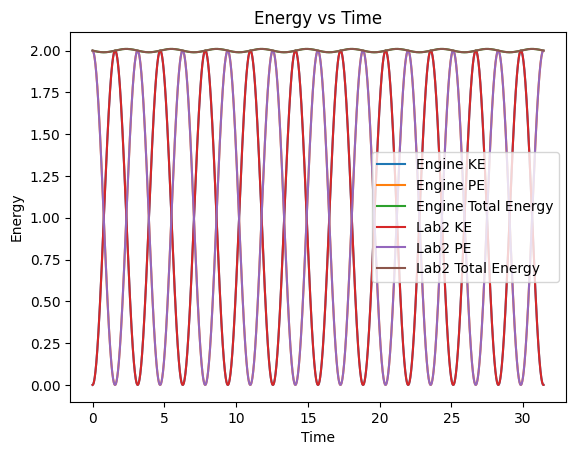

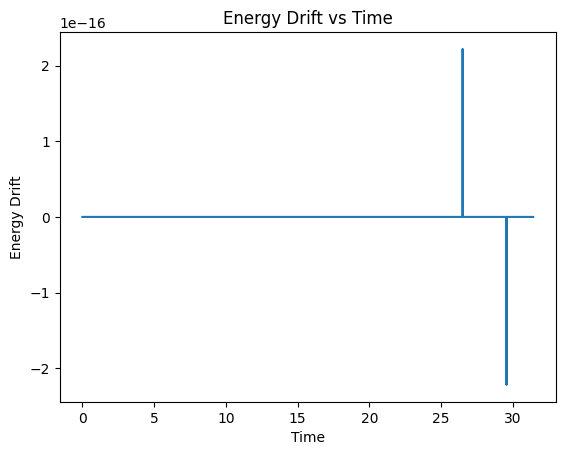

The max difference in total energy between the methods is 2.220446049250313e-16


In [91]:
Sim.record('x', lambda W: W.bodies[1].r[0])
Sim.record('KE', lambda W: W.kinetic_energy())
Sim.record('PE', lambda W: W.potential_energy())
Sim.record('E', lambda W: W.total_energy())
Sim.record('t', lambda W: W.t)
Sim.run(dt, end_t=5*T)

Lab3 = simulate_sho('euler-cromer', dt)

plt.plot(Sim.history['t'], Sim.history['x'], label= 'Engine Disp')
plt.plot(Lab3['t'], Lab3['x'], label='Lab3 Disp')
plt.xlabel('Time')
plt.ylabel('Displacement')
plt.title('Displacement vs Time')
plt.legend()
plt.show()

plt.plot(Sim.history['t'], Sim.history['KE'], label= 'Engine KE')
plt.plot(Sim.history['t'], Sim.history['PE'], label= 'Engine PE')
plt.plot(Sim.history['t'], Sim.history['E'], label= 'Engine Total Energy')

plt.plot(Lab3['t'], Lab3['KE'], label= 'Lab2 KE')
plt.plot(Lab3['t'], Lab3['PE'], label= 'Lab2 PE')
plt.plot(Lab3['t'], Lab3['E'], label= 'Lab2 Total Energy')

plt.xlabel('Time')
plt.ylabel('Energy')
plt.title('Energy vs Time')
plt.legend()
plt.show()

plt.plot(Sim.history['t'], [s-p for s, p in zip(Sim.history['E'],Lab3['E'])])
plt.xlabel('Time')
plt.ylabel('Energy Drift')
plt.title('Energy Drift vs Time')
plt.show()

print(f'The max difference in total energy between the methods is {max([s-p for s, p in zip(Sim.history['E'],Lab3['E'])])}')


Orbits

In lab 5, we looked at orbital motion. I have pasted the code I used for one of the parts of lab 5 and recreated the simulation using my engine. From the plots, it is clear that the engine and the code from lab 5 agree. Indeed, the max values for energy drift and angular momentum drift between the two simulations is on the order of 10e-14, so there is no virtually no discrepency between the simulations. 

In [97]:
def verlet_step(r, v, a, dt, accel_func):
    r_new = r + v*dt + 0.5*a*dt**2
    a_new = accel_func(r_new)
    v_new = v + 0.5*(a+a_new)*dt
    return r_new, a_new, v_new

G = 1
M = 1

def accel(r, r2 = np.array([0,0]), m2=M):
    return -G*m2*(r-r2)/(np.linalg.norm(r-r2)**3)

def energy(r, v, G=1.0, M=1.0, m=1.0):
    ke = 0.5*m*np.dot(v,v)
    pe = -G*M*m/np.linalg.norm(r)
    return ke + pe

def angular_momentum(r, v, M=1.0, m=1.0):
    return m * (r[0]*v[1] - r[1]*v[0])

r = np.array([1, 0])
v = np.array([0, 0.8])
a = accel(r)
dt = 0.001
t = 0
t_list = [0]
r_list = [r.copy()]
E = energy(r, v)
E_list = [E]
L = angular_momentum(r, v)
L_list = [L]

B1 = eng.Body(m=M, fixed=True)
B2 = eng.Body(m=M, r=r.copy(), v=v.copy())
Sim = eng.World(integrator=eng.Verlet(), forces=[eng.Newtonian_Gravity(G=G)], bodies=[B1, B2])


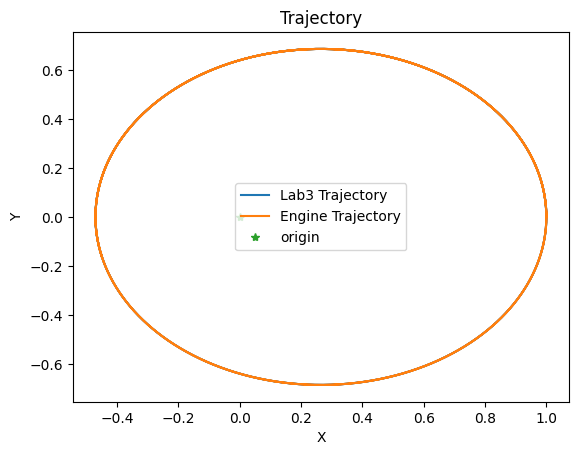

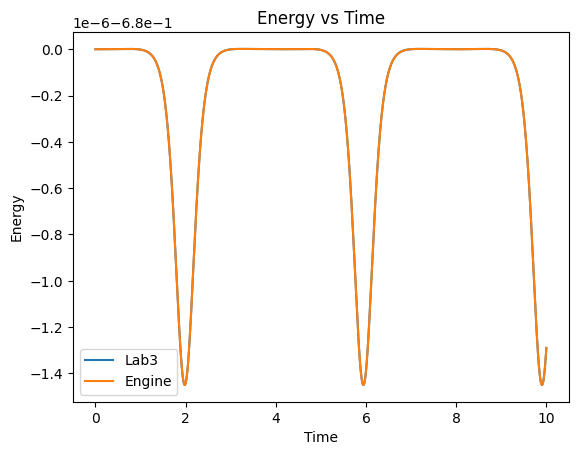

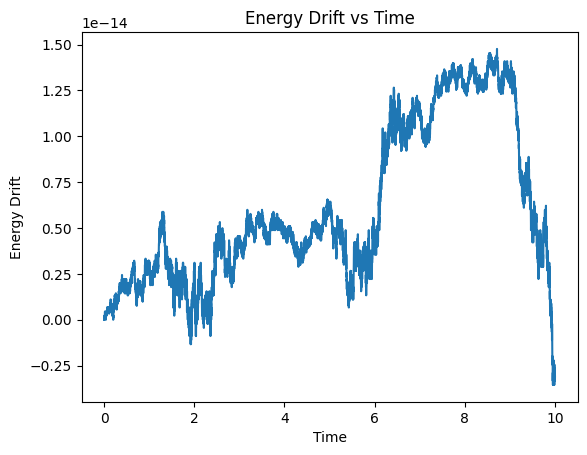

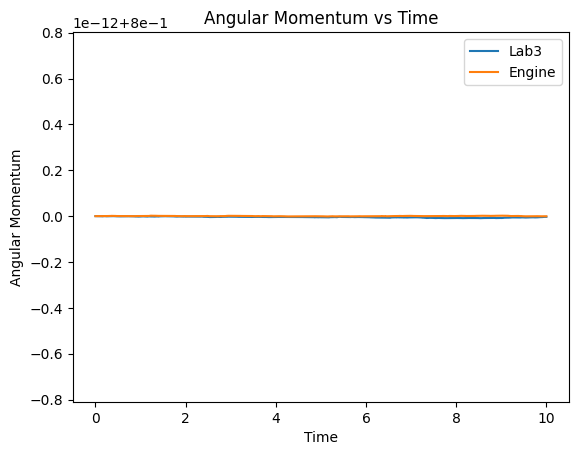

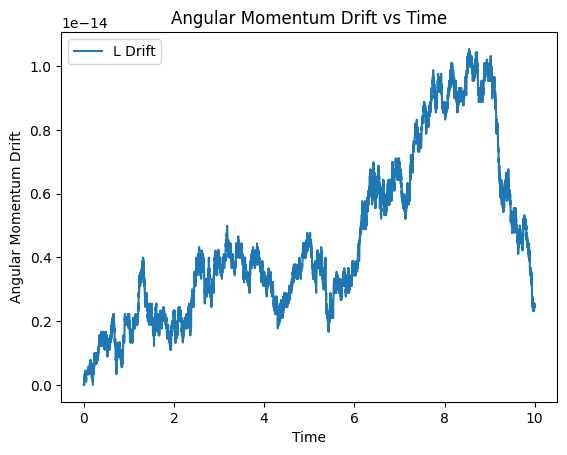

The max difference in total energy between methods is 1.4765966227514582e-14
The max difference in angular between methods is 1.0547118733938987e-14


In [98]:
Sim.record('r', lambda W: W.bodies[1].r.copy())
Sim.record('E', lambda W: W.total_energy())
Sim.record('t', lambda W: W.t)
Sim.record('L', lambda W: 
           W.bodies[1].r[0]*W.bodies[1].v[1]-W.bodies[1].r[1]*W.bodies[1].v[0])
Sim.run(dt, end_t=10)

while t < 10:
    t += dt
    r, a, v = verlet_step(r, v, a, dt, accel)
    E = energy(r, v)
    L = angular_momentum(r, v)
    t_list.append(t)
    r_list.append(r.copy())
    E_list.append(E)
    L_list.append(L)

r_list = np.array(r_list)
E_list = np.array(E_list)
plt.plot(r_list[:, 0], r_list[:, 1], label='Lab3 Trajectory')
plt.plot(np.array(Sim.history['r'])[:, 0], np.array(Sim.history['r'])[:, 1], label='Engine Trajectory')
plt.plot(0, 0, '*', label='origin')
plt.title('Trajectory')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

plt.plot(t_list, E_list, label='Lab3')
plt.plot(Sim.history['t'], Sim.history['E'], label='Engine')
plt.xlabel('Time')
plt.ylabel('Energy')
plt.title('Energy vs Time')
plt.legend()
plt.show()

plt.plot(Sim.history['t'], [s-p for s, p in zip(Sim.history['E'],E_list)])
plt.xlabel('Time')
plt.ylabel('Energy Drift')
plt.title('Energy Drift vs Time')
plt.show()

plt.plot(t_list, L_list, label= 'Lab3')
plt.plot(Sim.history['t'], Sim.history['L'], label= 'Engine')
plt.xlabel('Time')
plt.ylabel('Angular Momentum')
plt.title('Angular Momentum vs Time')
plt.legend()
plt.show()

plt.plot(Sim.history['t'], [l-L for l, L in zip(Sim.history['L'],L_list)], label= 'L Drift')
plt.xlabel('Time')
plt.ylabel('Angular Momentum Drift')
plt.title('Angular Momentum Drift vs Time')
plt.legend()
plt.show()

print(f'The max difference in total energy between methods is {max([s-p for s, p in zip(Sim.history['E'],E_list)])}')
print(f'The max difference in angular between methods is {max([l-L for l, L in zip(Sim.history['L'],L_list)])}')

Part C - Colliding Balls With Gravity

Below is a simulation of ten balls bouncing in a non-regular pentagonal box, with total energy used as a diagnostic. As the walls impart an impulse into the balls whenever a ball-wall collision occurs, momentum is not conserved, so it cannot be used as a diagnostic. As seen in the plot of energy over time for each dt, energy is not completely conserved by the simulation either. However, as dt decreases towards zero, the max energy drift trends to zero as well, so we see that over a relatively short time period, with a relatively small value for dt, the simulation approximately conserves energy.

KeyboardInterrupt: 

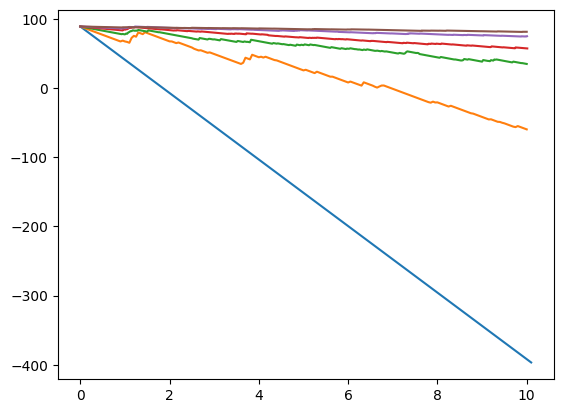

In [100]:
dt_list = []
dE_max = []
for i in range(8):
    dt = 0.1*2**(-i)
    bodies=[eng.Body(r=(0.2,0.1),v=(-1,0.4),radius=0.5), eng.Body(r=(3,0.6),v=(-0.2,-0.4),radius=0.5),
            eng.Body(r=(-2.1,-0.5),v=(0.6,1),radius=0.5), eng.Body(r=(0.4,-1.1),v=(0.8,0.4),radius=0.5),
            eng.Body(r=(-1.2,3.1),v=(-1.1,0.2),radius=0.5), eng.Body(r=(-0.2,1.1),v=(-1.1,-0.2),radius=0.5),
            eng.Body(r=(2.2,1.1),v=(0.3,0.7),radius=0.5), eng.Body(r=(0.7,3.1),v=(0.8,1.4),radius=0.5),
            eng.Body(r=(-0.7,-0.1),v=(0.5,-0.4),radius=0.5), eng.Body(r=(1.2,1.1),v=(0.2,1.4),radius=0.5)]
    W1,W2,W3,W4,W5 = [eng.Wall((-5,-5),(-5,5)),eng.Wall((-5,5),(5,5)),
                eng.Wall((5,5),(5,-5)),eng.Wall((5,-5),(0,-6)),eng.Wall((0,-6),(-5,-5))]
    Box=eng.World(integrator=eng.Euler_Cromer(),forces=[eng.Gravity()],bodies=bodies, walls=[W1,W2,W3,W4,W5],
                constraints=[eng.Body_Collisions(), eng.Wall_Collisions()], x_ext=(-5.1,5.1), y_ext=(-6.1,5.1), grid_n=20)
    Box.record('t', lambda W: W.t)
    Box.record('E', lambda W: W.total_energy())
    Box.record('PE', lambda W: W.potential_energy())
    Box.record('KE', lambda W: W.kinetic_energy())
    Box.run(dt, end_t=10)
    dt_list.append(dt)
    dE_max.append(max([abs(E-Box.history['E'][0]) for E in Box.history['E']]))
    plt.plot(Box.history['t'], Box.history['E'], label=f'dt = {dt}')

plt.legend()
plt.show()
plt.plot(dt_list, dE_max)
plt.xlim((0.1,0))
plt.ylim((0,500))
plt.show()
bodies=[eng.Body(r=(0.2,0.1),v=(-1,0.4),radius=0.5), eng.Body(r=(3,0.6),v=(-0.2,-0.4),radius=0.5),
        eng.Body(r=(-2.1,-0.5),v=(0.6,1),radius=0.5), eng.Body(r=(0.4,-1.1),v=(0.8,0.4),radius=0.5),
        eng.Body(r=(-1.2,3.1),v=(-1.1,0.2),radius=0.5), eng.Body(r=(-0.2,1.1),v=(-1.1,-0.2),radius=0.5),
        eng.Body(r=(2.2,1.1),v=(0.3,0.7),radius=0.5), eng.Body(r=(0.7,3.1),v=(0.8,1.4),radius=0.5),
        eng.Body(r=(-0.7,-0.1),v=(0.5,-0.4),radius=0.5), eng.Body(r=(1.2,1.1),v=(0.2,1.4),radius=0.5)]
Box=eng.World(integrator=eng.Euler_Cromer(),forces=[eng.Gravity()],bodies=bodies, walls=[W1,W2,W3,W4,W5],
            constraints=[eng.Body_Collisions(), eng.Wall_Collisions()], x_ext=(-5.1,5.1), y_ext=(-6.1,5.1), grid_n=20)
animate.animate_world(Box, 0.01, x_ext=(-5.1,5.1), y_ext=(-6.1,5.1), frames=1000, 
                      show={'Energy': lambda W: W.total_energy(), 't': lambda W: W.t})

Bonuse - Spatial Gridding

Below is a plot of runtime vs N for simulations with broad phase optimization (spatial gridding) and without. As we can see, from the broad phase optimation plot, the runtime grows linearly with N, and from the without broad phase optimization plot, the runtime grows quadratically with N. This is what we expect to see.

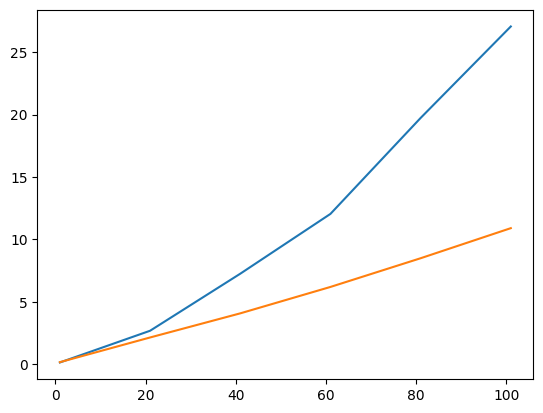

In [ ]:
n = 1
m = 100
r_dist = np.linspace(-5,5,200)
v_dist = np.linspace(-1,1,100)
n_list = []
runtime_list_no_grid=[]
runtime_list_grid=[]
for i in range(1,m+20,20):
    n_list.append(n*i)
    Bodies = []
    Walls = [eng.Wall((-5,-5),(-5,5)),eng.Wall((-5,5),(5,5)),eng.Wall((5,5),(5,-5)),eng.Wall((5,-5),(-5,-5))]
    for j in range(n*i):
        Bodies.append(eng.Body(r=rng.choice(r_dist, size=2), v=rng.choice(v_dist, size=2), radius=0.2))
    Box=eng.World(integrator=eng.Euler_Cromer(), bodies=Bodies, walls=Walls, 
                  constraints=[eng.Body_Collisions(),eng.Wall_Collisions()])
    start_time=time.perf_counter()
    Box.run(0.01, end_t=10)
    end_time=time.perf_counter()
    runtime_list_no_grid.append(end_time-start_time)
    for j in range(n*i):
        Bodies.append(eng.Body(r=rng.choice(r_dist, size=2), v=rng.choice(v_dist, size=2), radius=0.2))
    Box=eng.World(integrator=eng.Euler_Cromer(), bodies=Bodies, walls=Walls, 
                  constraints=[eng.Body_Collisions(),eng.Wall_Collisions()], x_ext=(-5,5),y_ext=(-5,5),grid_n=50)
    start_time=time.perf_counter()
    Box.run(0.01, end_t=10)
    end_time=time.perf_counter()
    runtime_list_grid.append(end_time-start_time)
plt.plot(n_list, runtime_list_no_grid, label='No Spatial Gridding')
plt.plot(n_list, runtime_list_grid, label='Spatial Gridding')
plt.legend()